# Notebook 09 — GraphTCDR Cold-Drug Baseline

## Objective

This notebook implements a GraphTCDR-based model for cancer drug-response
prediction using the prepared pancreatic cancer dataset.

The primary response target is:

**log10(IC50)**

The primary evaluation setting is:

**Cold-drug prediction**

where drugs in the test set are completely unseen during model training.

---

## Verified Data and Experimental Setup

The previous phases established:

- 28 pancreatic cancer cell lines matched to GraphTCDR multi-omics data
- 18,037 unique cell–drug response pairs
- 1,228 drugs with valid molecular fingerprints
- 2,048-bit Morgan molecular fingerprints
- 512-dimensional Autoencoder cell representations
- 982 training drugs
- 246 held-out test drugs
- 14,235 training response pairs
- 3,802 test response pairs
- zero train/test drug overlap
- 7,370 training-only response-derived cell–drug edges
- explicit mapping from the original 402-cell indices to local 28-cell
  pancreatic graph nodes

---

## Leakage-Control Principle

The fixed cold-drug split is reused throughout the modelling experiment.

Response-derived graph edges are constructed from training responses only.

Therefore, response information from the 246 held-out test drugs must not
be used during model training or response-derived graph construction.

Molecular information for test drugs may still be available through their
molecular fingerprints because the cold-drug task assumes that the chemical
structure of an unseen drug is available at prediction time.

---

## Model Implementation Principle

The GraphTCDR reference implementation will be inspected before the model
is implemented.

The reference architecture will be reproduced where appropriate.

Any project-specific adaptation will be explicitly documented.

No architectural component will be assumed or invented without verification.

## Target and Output Adaptation

The primary prediction target is the unscaled log10(IC50).

Unlike the original GraphTCDR implementation, which uses a normalized
response target with a Sigmoid output, the present study uses a linear
regression output so that the model can predict the full real-valued
log10(IC50) range.

This target/output formulation will later be evaluated through a
target-scaling sensitivity analysis.
---

## Experimental Sequence

1. Verify the computational environment
2. Inspect the GraphTCDR reference implementation
3. Document the verified architecture
4. Load the prepared graph components
5. Construct the leakage-controlled graph
6. Perform a model forward-pass test
7. Train the GraphTCDR baseline
8. Evaluate on the frozen cold-drug test set
9. Analyse overall and response-range performance
10. Save the trained model, predictions and evaluation results

The GraphTCDR baseline will be established before testing the proposed
tail-aware or curve-fit-quality-aware extensions.

verifying the the computational environmnet for the GRAPHTCDR

In [21]:
import sys
import torch

print("=" * 70)
print("GRAPHTCDR ENVIRONMENT VERIFICATION")
print("=" * 70)

print("Python executable:")
print(sys.executable)

print("\nPyTorch version:")
print(torch.__version__)

print("\nCUDA available:")
print(torch.cuda.is_available())

if torch.cuda.is_available():
    print("\nGPU:")
    print(torch.cuda.get_device_name(0))

    print("\nCUDA version reported by PyTorch:")
    print(torch.version.cuda)

print("\n" + "=" * 70)
print("✓ ENVIRONMENT CHECK COMPLETED")
print("=" * 70)

GRAPHTCDR ENVIRONMENT VERIFICATION
Python executable:
d:\Pancreatic_GraphTCDR\.venv\Scripts\python.exe

PyTorch version:
2.11.0+cu128

CUDA available:
True

GPU:
NVIDIA GeForce RTX 3050 A Laptop GPU

CUDA version reported by PyTorch:
12.8

✓ ENVIRONMENT CHECK COMPLETED


Load the prepared components

This step verifies the availability of the processed data files required for
the GraphTCDR baseline implementation.

The processed and split directories are checked to confirm that the required
files are present before they are loaded for modelling.

In [22]:
from pathlib import Path

project_dir = Path("..")

print("=" * 70)
print("GRAPH TCDR — PREPARED FILE CHECK")
print("=" * 70)

folders = [
    project_dir / "data" / "processed",
    project_dir / "data" / "processed" / "splits",
]

for folder in folders:
    print(f"\n📁 {folder}")
    
    if folder.exists():
        for file in sorted(folder.iterdir()):
            if file.is_file():
                print("   ", file.name)
    else:
        print("    Folder not found")

print("\n" + "=" * 70)
print("FILE CHECK COMPLETED")
print("=" * 70)

GRAPH TCDR — PREPARED FILE CHECK

📁 ..\data\processed
    autoencoder_best.pt
    drug_adjacency_fingerprint_threshold075.npy
    drug_morgan_fingerprints_1228x2048.npy
    drug_similarity_fingerprint_threshold075.npy
    drug_smiles_1228.csv
    integrated_modeling_table.csv
    integrated_with_auc.csv
    pancreatic28_ae_embeddings_512.csv
    pancreatic28_cell_adjacency_methylation_threshold075.npy
    pancreatic28_cell_mapping.csv
    pancreatic28_cell_similarity_methylation.npy
    pancreatic28_cnv.pt
    pancreatic28_gene_expression.pt
    pancreatic28_methylation.pt
    pancreatic28_mirna.pt
    targets_raw_v1.csv
    train_response_cell_drug_edges_lower50.csv
    train_response_drug_edge_summary.csv

📁 ..\data\processed\splits
    cold_drug_test.csv
    cold_drug_train.csv

FILE CHECK COMPLETED


In [23]:
from pathlib import Path

project_dir = Path("..")
split_dir = project_dir / "data" / "processed" / "splits"

print("FILES IN COLD-DRUG SPLIT DIRECTORY")
print("=" * 60)

if split_dir.exists():
    for file in sorted(split_dir.iterdir()):
        print(file.name)
else:
    print("Split directory not found:", split_dir.resolve())

FILES IN COLD-DRUG SPLIT DIRECTORY
cold_drug_test.csv
cold_drug_train.csv


## Step 5 — Load and Verify the Cold-Drug Split

This step loads the saved training and test datasets and verifies their dimensions, response-target values, and drug identities. It also checks that no drug identity is shared between the training and test sets.

In [24]:
import pandas as pd
from pathlib import Path

project_dir = Path("..")
split_dir = project_dir / "data" / "processed" / "splits"

train_df = pd.read_csv(split_dir / "cold_drug_train.csv")
test_df = pd.read_csv(split_dir / "cold_drug_test.csv")

print("TRAIN DATA")
print("Shape:", train_df.shape)
print("Columns:", train_df.columns.tolist())

print("\nTEST DATA")
print("Shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())

print("\nDrug overlap:")
print(
    len(
        set(train_df["name"].dropna())
        & set(test_df["name"].dropna())
    )
)

print("\nMissing training targets:", train_df["log_ic50"].isna().sum())
print("Missing test targets:", test_df["log_ic50"].isna().sum())

TRAIN DATA
Shape: (14235, 7)
Columns: ['depmap_id', 'ccle_name', 'omics_index', 'name', 'drug_index', 'log_ic50', 'r2']

TEST DATA
Shape: (3802, 7)
Columns: ['depmap_id', 'ccle_name', 'omics_index', 'name', 'drug_index', 'log_ic50', 'r2']

Drug overlap:
0

Missing training targets: 0
Missing test targets: 0


Verify the prepared feature dimensions

## Step 6 — Inspect Prepared Feature Dimensions

This step loads the prepared feature arrays and tensors to inspect their dimensions and data types. These checks help establish whether the available cell-line and drug representations are compatible with the GraphTCDR implementation.

In [25]:
from pathlib import Path
import numpy as np
import torch

project_dir = Path("..")
data_dir = project_dir / "data" / "processed"

files = [
    "pancreatic28_gene_expression.pt",
    "pancreatic28_cnv.pt",
    "pancreatic28_methylation.pt",
    "pancreatic28_mirna.pt",
]

for filename in files:
    path = data_dir / filename
    obj = torch.load(path, map_location="cpu", weights_only=True)

    print(f"\n{filename}")
    print("Type:", type(obj))

    if isinstance(obj, torch.Tensor):
        print("Shape:", tuple(obj.shape))
        print("Data type:", obj.dtype)
    elif isinstance(obj, dict):
        print("Keys:", list(obj.keys()))
    else:
        print("Object loaded successfully")

fingerprints = np.load(
    data_dir / "drug_morgan_fingerprints_1228x2048.npy"
)
cell_adjacency = np.load(
    data_dir / "pancreatic28_cell_adjacency_methylation_threshold075.npy"
)
drug_adjacency = np.load(
    data_dir / "drug_adjacency_fingerprint_threshold075.npy"
)

print("\nDrug fingerprints")
print("Shape:", fingerprints.shape)
print("Data type:", fingerprints.dtype)

print("\nCell adjacency matrix")
print("Shape:", cell_adjacency.shape)

print("\nDrug adjacency matrix")
print("Shape:", drug_adjacency.shape)


pancreatic28_gene_expression.pt
Type: <class 'torch.Tensor'>
Shape: (28, 20404)
Data type: torch.float32

pancreatic28_cnv.pt
Type: <class 'torch.Tensor'>
Shape: (28, 22582)
Data type: torch.float32

pancreatic28_methylation.pt
Type: <class 'torch.Tensor'>
Shape: (28, 20587)
Data type: torch.float32

pancreatic28_mirna.pt
Type: <class 'torch.Tensor'>
Shape: (28, 734)
Data type: torch.float32

Drug fingerprints
Shape: (1228, 2048)
Data type: uint8

Cell adjacency matrix
Shape: (28, 28)

Drug adjacency matrix
Shape: (1228, 1228)


Verify drug and cell index mappings

checks the correspondence between the drug and cell identifiers in the modelling tables and the prepared feature mappings. Consistent indexing is necessary to associate each response observation with the correct cell-line and drug representations.

In [26]:
from pathlib import Path
import pandas as pd

project_dir = Path("..")
data_dir = project_dir / "data" / "processed"
split_dir = data_dir / "splits"

train_df = pd.read_csv(split_dir / "cold_drug_train.csv")
test_df = pd.read_csv(split_dir / "cold_drug_test.csv")
cell_mapping = pd.read_csv(data_dir / "pancreatic28_cell_mapping.csv")
drug_smiles = pd.read_csv(data_dir / "drug_smiles_1228.csv")

print("CELL MAPPING")
print("Shape:", cell_mapping.shape)
print("Columns:", cell_mapping.columns.tolist())
print(cell_mapping.head())

print("\nDRUG MAPPING")
print("Shape:", drug_smiles.shape)
print("Columns:", drug_smiles.columns.tolist())
print(drug_smiles.head())

print("\nINDEX RANGES")
print("Training drug_index:", train_df["drug_index"].min(),
      "to", train_df["drug_index"].max())
print("Test drug_index:", test_df["drug_index"].min(),
      "to", test_df["drug_index"].max())
print("Unique drug indices in all responses:",
      pd.concat([train_df["drug_index"], test_df["drug_index"]]).nunique())

print("\nCell omics_index range:",
      pd.concat([train_df["omics_index"], test_df["omics_index"]]).min(),
      "to",
      pd.concat([train_df["omics_index"], test_df["omics_index"]]).max())

CELL MAPPING
Shape: (28, 2)
Columns: ['index', 'cellLineName']
   index        cellLineName
0      0  PATU8988S_PANCREAS
1     39   PANC0327_PANCREAS
2     47      PANC1_PANCREAS
3     68       PSN1_PANCREAS
4     79      SUIT2_PANCREAS

DRUG MAPPING
Shape: (1228, 2)
Columns: ['name', 'canonical_smiles']
          name                                   canonical_smiles
0  floxuridine       O=c1[nH]c(=O)n(C2C[C@@H](O)[C@@H](CO)O2)cc1F
1   valrubicin  CCCCC(=O)OCC(=O)[C@]1(O)Cc2c(O)c3c(c(O)c2[C@@H...
2    adapalene  COc1ccc(-c2ccc3cc(C(=O)O)ccc3c2)cc1C12CC3CC(CC...
3  fulvestrant  C[C@]12CC[C@@H]3c4ccc(O)cc4C[C@@H](CCCCCCCCCS(...
4   belinostat           O=C(/C=C/c1cccc(S(=O)(=O)Nc2ccccc2)c1)NO

INDEX RANGES
Training drug_index: 0 to 1226
Test drug_index: 4 to 1227
Unique drug indices in all responses: 1228

Cell omics_index range: 0 to 400


Verify Cell-Line Index Alignment

compares the cell indices in the response tables with the prepared pancreatic cell mapping. It determines whether the response-table indices correspond to local tensor row positions or to indices from the original reference dataset.

In [27]:
from pathlib import Path
import pandas as pd

project_dir = Path("..")
data_dir = project_dir / "data" / "processed"
split_dir = data_dir / "splits"

train_df = pd.read_csv(split_dir / "cold_drug_train.csv")
test_df = pd.read_csv(split_dir / "cold_drug_test.csv")
cell_mapping = pd.read_csv(data_dir / "pancreatic28_cell_mapping.csv")

response_cells = pd.concat(
    [train_df[["depmap_id", "ccle_name", "omics_index"]],
     test_df[["depmap_id", "ccle_name", "omics_index"]]],
    ignore_index=True
).drop_duplicates()

print("Response-table cell indices:")
print(sorted(response_cells["omics_index"].dropna().unique()))

print("\nCell-mapping indices:")
print(sorted(cell_mapping["index"].unique()))

print("\nCell mapping preview:")
print(cell_mapping.to_string(index=False))

print("\nResponse-table cell preview:")
print(response_cells.head(10).to_string(index=False))

Response-table cell indices:
[np.int64(0), np.int64(39), np.int64(47), np.int64(68), np.int64(79), np.int64(84), np.int64(85), np.int64(91), np.int64(103), np.int64(123), np.int64(135), np.int64(160), np.int64(165), np.int64(166), np.int64(179), np.int64(234), np.int64(237), np.int64(266), np.int64(291), np.int64(294), np.int64(313), np.int64(319), np.int64(321), np.int64(333), np.int64(362), np.int64(384), np.int64(386), np.int64(400)]

Cell-mapping indices:
[np.int64(0), np.int64(39), np.int64(47), np.int64(68), np.int64(79), np.int64(84), np.int64(85), np.int64(91), np.int64(103), np.int64(123), np.int64(135), np.int64(160), np.int64(165), np.int64(166), np.int64(179), np.int64(234), np.int64(237), np.int64(266), np.int64(291), np.int64(294), np.int64(313), np.int64(319), np.int64(321), np.int64(333), np.int64(362), np.int64(384), np.int64(386), np.int64(400)]

Cell mapping preview:
 index       cellLineName
     0 PATU8988S_PANCREAS
    39  PANC0327_PANCREAS
    47     PANC1_PANCRE

Validate Cell-Line Index Mapping

verifies that each original cell index maps to exactly one row in the prepared 28-cell dataset. It also checks that all response-table cell indices are represented in the mapping.

In [28]:
from pathlib import Path
import pandas as pd

project_dir = Path("..")
data_dir = project_dir / "data" / "processed"
split_dir = data_dir / "splits"

train_df = pd.read_csv(split_dir / "cold_drug_train.csv")
test_df = pd.read_csv(split_dir / "cold_drug_test.csv")
cell_mapping = pd.read_csv(data_dir / "pancreatic28_cell_mapping.csv")

response_indices = set(
    pd.concat([
        train_df["omics_index"],
        test_df["omics_index"]
    ]).dropna().astype(int)
)

mapping_indices = set(cell_mapping["index"].astype(int))

print("Mapping rows:", len(cell_mapping))
print("Unique original indices:", cell_mapping["index"].nunique())
print("Duplicate original indices:", cell_mapping["index"].duplicated().sum())
print("Response indices missing from mapping:",
      sorted(response_indices - mapping_indices))
print("Mapping indices unused by responses:",
      sorted(mapping_indices - response_indices))

print("\nMapping validation completed.")

Mapping rows: 28
Unique original indices: 28
Duplicate original indices: 0
Response indices missing from mapping: []
Mapping indices unused by responses: []

Mapping validation completed.


Create Local Cell Indices

The original cell indices are not contiguous from 0 to 27. This step creates a mapping from each original cell index to its corresponding local row position in the prepared 28-cell feature tensors.

In [29]:
from pathlib import Path
import pandas as pd

project_dir = Path("..")
data_dir = project_dir / "data" / "processed"

cell_mapping = pd.read_csv(
    data_dir / "pancreatic28_cell_mapping.csv"
)

# Map each original index to its local tensor row position.
cell_mapping["local_index"] = range(len(cell_mapping))

original_to_local = dict(
    zip(
        cell_mapping["index"].astype(int),
        cell_mapping["local_index"].astype(int)
    )
)

print("Original-to-local cell mapping (first 10):")
for original_index, local_index in list(original_to_local.items())[:10]:
    print(f"Original index {original_index} -> local index {local_index}")

print("\nTotal mapped cells:", len(original_to_local))

Original-to-local cell mapping (first 10):
Original index 0 -> local index 0
Original index 39 -> local index 1
Original index 47 -> local index 2
Original index 68 -> local index 3
Original index 79 -> local index 4
Original index 84 -> local index 5
Original index 85 -> local index 6
Original index 91 -> local index 7
Original index 103 -> local index 8
Original index 123 -> local index 9

Total mapped cells: 28


 Verify Drug-Index Alignment

checks whether the drug indices in the response tables are consistent with the row positions in the prepared molecular fingerprint matrix and drug adjacency matrix.

In [30]:
from pathlib import Path
import numpy as np
import pandas as pd

project_dir = Path("..")
data_dir = project_dir / "data" / "processed"
split_dir = data_dir / "splits"

train_df = pd.read_csv(split_dir / "cold_drug_train.csv")
test_df = pd.read_csv(split_dir / "cold_drug_test.csv")

fingerprints = np.load(
    data_dir / "drug_morgan_fingerprints_1228x2048.npy"
)

drug_adjacency = np.load(
    data_dir / "drug_adjacency_fingerprint_threshold075.npy"
)

all_drug_indices = pd.concat(
    [train_df["drug_index"], test_df["drug_index"]],
    ignore_index=True
).dropna().astype(int)

print("Fingerprint rows:", fingerprints.shape[0])
print("Drug adjacency nodes:", drug_adjacency.shape[0])
print("Unique response-table drug indices:", all_drug_indices.nunique())
print("Minimum drug index:", all_drug_indices.min())
print("Maximum drug index:", all_drug_indices.max())

expected_indices = set(range(fingerprints.shape[0]))
observed_indices = set(all_drug_indices.unique())

print("Response indices outside fingerprint range:",
      sorted(observed_indices - expected_indices))
print("Fingerprint indices absent from response tables:",
      sorted(expected_indices - observed_indices))

print("\nDrug-index verification completed.")

Fingerprint rows: 1228
Drug adjacency nodes: 1228
Unique response-table drug indices: 1228
Minimum drug index: 0
Maximum drug index: 1227
Response indices outside fingerprint range: []
Fingerprint indices absent from response tables: []

Drug-index verification completed.


Verify drug identity alignment

 compares the drug names and molecular structures in the prepared drug mapping with the drug identities recorded in the response tables. It checks whether the same drug index consistently identifies the same compound across the prepared data files.

In [31]:
from pathlib import Path
import pandas as pd

project_dir = Path("..")
data_dir = project_dir / "data" / "processed"
split_dir = data_dir / "splits"

train_df = pd.read_csv(split_dir / "cold_drug_train.csv")
test_df = pd.read_csv(split_dir / "cold_drug_test.csv")
drug_mapping = pd.read_csv(data_dir / "drug_smiles_1228.csv")

responses = pd.concat([train_df, test_df], ignore_index=True)

# Check whether each response-table drug index maps to one drug name.
names_per_index = responses.groupby("drug_index")["name"].nunique()

# Check whether each drug name maps to one index.
indices_per_name = responses.groupby("name")["drug_index"].nunique()

print("Drug mapping rows:", len(drug_mapping))
print("Duplicate drug names in mapping:", drug_mapping["name"].duplicated().sum())
print("Response indices with multiple names:", (names_per_index > 1).sum())
print("Response names with multiple indices:", (indices_per_name > 1).sum())

print("\nFirst five response-table drug mappings:")
print(
    responses[["drug_index", "name"]]
    .drop_duplicates()
    .sort_values("drug_index")
    .head()
    .to_string(index=False)
)

print("\nFirst five fingerprint-order drug mappings:")
print(drug_mapping.head().to_string(index=False))

Drug mapping rows: 1228
Duplicate drug names in mapping: 0
Response indices with multiple names: 0
Response names with multiple indices: 0

First five response-table drug mappings:
 drug_index        name
          0 floxuridine
          1  valrubicin
          2   adapalene
          3 fulvestrant
          4  belinostat

First five fingerprint-order drug mappings:
       name                                                                                                         canonical_smiles
floxuridine                                                                             O=c1[nH]c(=O)n(C2C[C@@H](O)[C@@H](CO)O2)cc1F
 valrubicin CCCCC(=O)OCC(=O)[C@]1(O)Cc2c(O)c3c(c(O)c2[C@@H](O[C@H]2C[C@H](NC(=O)C(F)(F)F)[C@H](O)[C@H](C)O2)C1)C(=O)c1c(OC)cccc1C3=O
  adapalene                                                                  COc1ccc(-c2ccc3cc(C(=O)O)ccc3c2)cc1C12CC3CC(CC(C3)C1)C2
fulvestrant                              C[C@]12CC[C@@H]3c4ccc(O)cc4C[C@@H](CCCCCCCCCS(=O)CCCC(F)(

Verify fingerprint and adjacency matrix properties

checks the dimensions, symmetry, diagonal values, and numerical properties of the prepared cell-line and drug adjacency matrices. These checks help verify that the matrices are structurally suitable for graph construction.

In [32]:
from pathlib import Path
import numpy as np

project_dir = Path("..")
data_dir = project_dir / "data" / "processed"

cell_adj = np.load(
    data_dir / "pancreatic28_cell_adjacency_methylation_threshold075.npy"
)
drug_adj = np.load(
    data_dir / "drug_adjacency_fingerprint_threshold075.npy"
)

for name, matrix in [
    ("Cell adjacency", cell_adj),
    ("Drug adjacency", drug_adj),
]:
    print(f"\n{name}")
    print("Shape:", matrix.shape)
    print("Data type:", matrix.dtype)
    print("All finite:", np.isfinite(matrix).all())
    print("Symmetric:", np.allclose(matrix, matrix.T))
    print("Diagonal values:", np.unique(np.diag(matrix))[:10])
    print("Unique values (first 10):", np.unique(matrix)[:10])
    print("Nonzero entries:", np.count_nonzero(matrix))
    print("Density:", np.count_nonzero(matrix) / matrix.size)


Cell adjacency
Shape: (28, 28)
Data type: float32
All finite: True
Symmetric: True
Diagonal values: [0.]
Unique values (first 10): [0. 1.]
Nonzero entries: 482
Density: 0.6147959183673469

Drug adjacency
Shape: (1228, 1228)
Data type: float32
All finite: True
Symmetric: True
Diagonal values: [0.]
Unique values (first 10): [0. 1.]
Nonzero entries: 434
Density: 0.00028780146208447834


the cell graph has a density of about 61.5%, while the drug graph has a density of only 0.029%. This difference is not automatically an error, but we should document it and verify how the reference GraphTCDR implementation expects these graph inputs to be constructed.

 Analyze Graph Connectivity

examines the connectivity of the prepared cell-line and drug graphs by counting isolated nodes and connected components. It provides a basic structural assessment of each graph before model integration.

In [33]:
from pathlib import Path
import numpy as np
from scipy.sparse.csgraph import connected_components

project_dir = Path("..")
data_dir = project_dir / "data" / "processed"

graphs = {
    "Cell graph": np.load(
        data_dir / "pancreatic28_cell_adjacency_methylation_threshold075.npy"
    ),
    "Drug graph": np.load(
        data_dir / "drug_adjacency_fingerprint_threshold075.npy"
    ),
}

for name, adjacency in graphs.items():
    n_components, labels = connected_components(
        adjacency,
        directed=False,
        return_labels=True,
    )

    degrees = adjacency.sum(axis=1)

    print(f"\n{name}")
    print("Nodes:", adjacency.shape[0])
    print("Edges:", int(np.count_nonzero(adjacency) // 2))
    print("Connected components:", n_components)
    print("Isolated nodes:", int(np.sum(degrees == 0)))
    print("Minimum degree:", int(degrees.min()))
    print("Maximum degree:", int(degrees.max()))
    print("Mean degree:", float(degrees.mean()))


Cell graph
Nodes: 28
Edges: 241
Connected components: 1
Isolated nodes: 0
Minimum degree: 4
Maximum degree: 26
Mean degree: 17.214284896850586

Drug graph
Nodes: 1228
Edges: 217
Connected components: 1068
Isolated nodes: 976
Minimum degree: 0
Maximum degree: 6
Mean degree: 0.3534201979637146


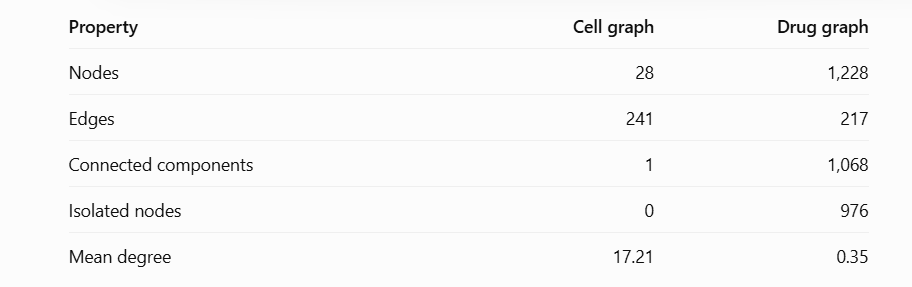

The cell graph is connected, whereas the drug graph is extremely sparse: 976 of 1,228 drugs have no neighbours in the prepared drug similarity graph.

we should investigate whether this sparsity is consistent with the reference GraphTCDR graph construction and whether the model can handle isolated drug nodes appropriately. We should not modify the threshold or rebuild the graph without checking the reference implementation first.

Inspect Reference Drug-Graph Construction

 examines the GraphTCDR reference implementation to identify how drug similarity is calculated, how drug graph edges are selected, and how the model handles drug nodes with no neighbours.

In [34]:
from pathlib import Path

repo = Path(r"D:\Pancreatic_GraphTCDR")

for path in repo.rglob("DrugCellProcessing.py"):
    if ".venv" not in str(path):
        print(path)

In [35]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFiles and folders here:")
for item in Path.cwd().iterdir():
    print(item.name)

Current working directory:
d:\Pancreatic_GraphTCDR\notebooks

Files and folders here:
01_PRISM_Data_Exploration.ipynb
02_MultiOmics_Feasibility.ipynb
03_Drug_Molecular_Features.ipynb
04_Integrated_Dataset_Preparation.ipynb
05_Baseline_ML_Models.ipynb
06_Tail_Diagnosis.ipynb
07_Target Construction & Autoencoder.ipynb
08_Multi-Omics Autoencoder Representation Learning.ipynb
09_GraphTCDR_ColdDrug_Baseline.ipynb
pre_graph_checks.py


In [36]:
from pathlib import Path

project = Path.cwd().parent

print("Project folder:", project)
print("\nPython files and folders:")
for item in project.iterdir():
    print(item.name)

Project folder: d:\Pancreatic_GraphTCDR

Python files and folders:
.git
.gitignore
.venv
audit_missing_ic50.py
data
notebooks
opencode_task.txt
pre_graph_checks.py
results
src


In [37]:
from pathlib import Path

project = Path.cwd().parent

matches = [
    p for p in project.rglob("DrugCellProcessing.py")
    if ".venv" not in p.parts
]

if matches:
    for path in matches:
        print("Found:", path)
else:
    print("DrugCellProcessing.py was not found inside the project.")

DrugCellProcessing.py was not found inside the project.


In [38]:
from pathlib import Path

project = Path.cwd().parent

for folder in ["src", "notebooks"]:
    root = project / folder
    for path in root.rglob("*.py"):
        if ".venv" in path.parts:
            continue
        try:
            content = path.read_text(encoding="utf-8")
            if any(term in content.lower() for term in [
                "drug_similarity",
                "fingerprint_threshold",
                "drug_adjacency"
            ]):
                print(f"\n--- {path.relative_to(project)} ---")
                for line_no, line in enumerate(content.splitlines(), 1):
                    if any(term in line.lower() for term in [
                        "drug_similarity",
                        "fingerprint_threshold",
                        "drug_adjacency",
                        "corrcoef",
                        "correlation"
                    ]):
                        print(f"{line_no}: {line.strip()}")
        except (UnicodeDecodeError, OSError):
            pass


--- notebooks\pre_graph_checks.py ---
61: da = np.load(os.path.join(PROC, "drug_adjacency_fingerprint_threshold075.npy"))


In [39]:
from pathlib import Path

project = Path.cwd().parent

for path in project.rglob("*.ipynb"):
    if ".venv" in path.parts:
        continue

    try:
        import json
        notebook = json.loads(path.read_text(encoding="utf-8"))

        for i, cell in enumerate(notebook.get("cells", [])):
            if cell.get("cell_type") != "code":
                continue

            source = "".join(cell.get("source", []))
            keywords = [
                "drug_similarity_fingerprint_threshold075",
                "corrcoef",
                "drug_adjacency_fingerprint_threshold075",
            ]

            if any(k in source.lower() for k in keywords):
                print(f"\nNotebook: {path.name} | Cell: {i}")
                print(source[:4000])
    except (OSError, ValueError):
        pass


Notebook: 08_Multi-Omics Autoencoder Representation Learning.ipynb | Cell: 73
# Save the drug-drug similarity and adjacency matrices

drug_similarity_path = os.path.join(
    PROJECT,
    "data",
    "processed",
    "drug_similarity_fingerprint_threshold075.npy"
)

drug_adjacency_path = os.path.join(
    PROJECT,
    "data",
    "processed",
    "drug_adjacency_fingerprint_threshold075.npy"
)

np.save(drug_similarity_path, drug_similarity)
np.save(drug_adjacency_path, drug_adjacency)

print("Saved drug similarity:")
print(drug_similarity_path)

print("\nSaved drug adjacency:")
print(drug_adjacency_path)

print("\nSimilarity shape:", drug_similarity.shape)
print("Adjacency shape:", drug_adjacency.shape)
print(
    "Undirected edges:",
    int(np.sum(np.triu(drug_adjacency, k=1)))
)

print("\n✓ DRUG-DRUG GRAPH SAVED")

Notebook: 08_Multi-Omics Autoencoder Representation Learning.ipynb | Cell: 87
# Reload previously saved graph components


import os
import numpy as np
import pandas as 

In [40]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

try:
    import torch_geometric
    from torch_geometric.nn import HGTConv

    print("PyTorch Geometric:", torch_geometric.__version__)
    print("HGTConv is available.")

except ImportError as e:
    print("Dependency issue:", e)

PyTorch: 2.11.0+cu128
CUDA available: True
Dependency issue: No module named 'torch_geometric'


In [42]:
%pip install torch-geometric

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached aiohappyeyeballs-2.7.1-py3-none-any.whl.metadata (5.9 kB)
  Using cached aiosignal-1.4.0-py3-none-any.whl.metadata (3.7 kB)
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 1.3/1.3 MB 13.6 MB/s  0:00:00
Using cached aiohappyeyeballs-2.7.1-py3-none-any.whl (15 kB)
Using cached aiosignal-1.4.0-py3-none-any.whl (7.5 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)

   --- ------------------------------------  1/11 [tqdm]
   ---------- -----------------------------  3/11 [multidict]
   ------------------------- --------------  7/11 [yarl]
   -------------------------------- -------  9/11 [aiohttp]
   -------------------------------- -------  9/11 [aiohttp]
   -------------------------------- -------  9/11 [aiohttp]
   ------------------------------------ --- 10/11 [torch-geometric]
   ------------------------------------ --- 10/11 [torch-geometric

In [43]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

try:
    import torch_geometric
    from torch_geometric.nn import HGTConv

    print("PyTorch Geometric:", torch_geometric.__version__)
    print("HGTConv is available.")

except ImportError as e:
    print("Dependency issue:", e)

PyTorch: 2.11.0+cu128
CUDA available: True
PyTorch Geometric: 2.8.1
HGTConv is available.


Inspect the HGTConv interface

In [44]:
import inspect
from torch_geometric.nn import HGTConv

print("HGTConv constructor:")
print(inspect.signature(HGTConv.__init__))

print("\nHGTConv forward method:")
print(inspect.signature(HGTConv.forward))

HGTConv constructor:
(self, in_channels: Union[int, Dict[str, int]], out_channels: int, metadata: Tuple[List[str], List[Tuple[str, str, str]]], heads: int = 1, **kwargs)

HGTConv forward method:
(self, x_dict: Dict[str, torch.Tensor], edge_index_dict: Dict[Tuple[str, str, str], Union[torch.Tensor, torch_geometric.typing.SparseTensor]]) -> Dict[str, Optional[torch.Tensor]]


In [45]:
from pathlib import Path
import pandas as pd

project_dir = Path("..")
data_dir = project_dir / "data" / "processed"

edge_path = data_dir / "train_response_cell_drug_edges_lower50.csv"
edges_df = pd.read_csv(edge_path)

print("Training-only response edges")
print("Shape:", edges_df.shape)
print("Columns:", edges_df.columns.tolist())
print("\nFirst five rows:")
print(edges_df.head().to_string(index=False))

Training-only response edges
Shape: (7370, 2)
Columns: ['omics_index', 'drug_index']

First five rows:
 omics_index  drug_index
          68           0
         291           0
         165           0
          39           0
         386           0


Build the heterogeneous graph

In [46]:
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from torch_geometric.data import HeteroData

project_dir = Path("..")
data_dir = project_dir / "data" / "processed"

# Load mappings
cell_mapping = pd.read_csv(
    data_dir / "pancreatic28_cell_mapping.csv"
)
original_to_local = dict(
    zip(
        cell_mapping["index"].astype(int),
        range(len(cell_mapping))
    )
)

# Load adjacency matrices
cell_adj = np.load(
    data_dir / "pancreatic28_cell_adjacency_methylation_threshold075.npy"
)
drug_adj = np.load(
    data_dir / "drug_adjacency_fingerprint_threshold075.npy"
)

# Load training-only response edges
edges_df = pd.read_csv(
    data_dir / "train_response_cell_drug_edges_lower50.csv"
)

# Convert original cell indices to local graph indices
edges_df["cell_local"] = edges_df["omics_index"].map(
    original_to_local
)

if edges_df["cell_local"].isna().any():
    raise ValueError("Some response edges have unmapped cell indices.")

# Convert adjacency matrices to edge indices
cell_edge_index = torch.tensor(
    np.vstack(np.where(cell_adj > 0)),
    dtype=torch.long
)

drug_edge_index = torch.tensor(
    np.vstack(np.where(drug_adj > 0)),
    dtype=torch.long
)

# Convert cell-drug response edges
response_edge_index = torch.tensor(
    np.vstack([
        edges_df["cell_local"].astype(int).to_numpy(),
        edges_df["drug_index"].astype(int).to_numpy()
    ]),
    dtype=torch.long
)

# Build heterogeneous graph structure
graph = HeteroData()

graph["cell"].num_nodes = len(cell_mapping)
graph["drug"].num_nodes = drug_adj.shape[0]

graph["cell", "similar", "cell"].edge_index = cell_edge_index
graph["drug", "similar", "drug"].edge_index = drug_edge_index

graph["cell", "response", "drug"].edge_index = response_edge_index
graph["drug", "rev_response", "cell"].edge_index = (
    response_edge_index.flip(0)
)

print("Heterogeneous graph structure")
print(graph)
print("\nCell nodes:", graph["cell"].num_nodes)
print("Drug nodes:", graph["drug"].num_nodes)
print("Cell-cell edges:", cell_edge_index.shape[1])
print("Drug-drug edges:", drug_edge_index.shape[1])
print("Training response edges:", response_edge_index.shape[1])
print("Reverse response edges:", response_edge_index.flip(0).shape[1])

Heterogeneous graph structure
HeteroData(
  cell={ num_nodes=28 },
  drug={ num_nodes=1228 },
  (cell, similar, cell)={ edge_index=[2, 482] },
  (drug, similar, drug)={ edge_index=[2, 434] },
  (cell, response, drug)={ edge_index=[2, 7370] },
  (drug, rev_response, cell)={ edge_index=[2, 7370] }
)

Cell nodes: 28
Drug nodes: 1228
Cell-cell edges: 482
Drug-drug edges: 434
Training response edges: 7370
Reverse response edges: 7370


Load cell and drug feature

In [47]:
import numpy as np
import pandas as pd
import torch
from pathlib import Path

data_dir = Path("..") / "data" / "processed"

# Load cell-line embeddings
cell_embeddings_df = pd.read_csv(
    data_dir / "pancreatic28_ae_embeddings_512.csv"
)

print("Cell embedding file shape:", cell_embeddings_df.shape)
print("Cell embedding columns:", cell_embeddings_df.columns[:5].tolist())

# Inspect available prepared fingerprint files
fingerprint_files = sorted(data_dir.glob("*fingerprint*.npy"))

print("\nPrepared fingerprint files:")
for path in fingerprint_files:
    arr = np.load(path, mmap_mode="r")
    print(f"{path.name}: shape={arr.shape}, dtype={arr.dtype}")

# Inspect the drug mapping
drug_mapping = pd.read_csv(data_dir / "drug_smiles_1228.csv")

print("\nDrug mapping shape:", drug_mapping.shape)
print("Drug mapping columns:", drug_mapping.columns.tolist())
print(drug_mapping.head(3).to_string(index=False))

Cell embedding file shape: (28, 513)
Cell embedding columns: ['cellLineName', 'AE_1', 'AE_2', 'AE_3', 'AE_4']

Prepared fingerprint files:
drug_adjacency_fingerprint_threshold075.npy: shape=(1228, 1228), dtype=float32
drug_morgan_fingerprints_1228x2048.npy: shape=(1228, 2048), dtype=uint8
drug_similarity_fingerprint_threshold075.npy: shape=(1228, 1228), dtype=float32

Drug mapping shape: (1228, 2)
Drug mapping columns: ['name', 'canonical_smiles']
       name                                                                                                         canonical_smiles
floxuridine                                                                             O=c1[nH]c(=O)n(C2C[C@@H](O)[C@@H](CO)O2)cc1F
 valrubicin CCCCC(=O)OCC(=O)[C@]1(O)Cc2c(O)c3c(c(O)c2[C@@H](O[C@H]2C[C@H](NC(=O)C(F)(F)F)[C@H](O)[C@H](C)O2)C1)C(=O)c1c(OC)cccc1C3=O
  adapalene                                                                  COc1ccc(-c2ccc3cc(C(=O)O)ccc3c2)cc1C12CC3CC(CC(C3)C1)C2




Both feature files are ready: 28 cell lines × 512 features and 1,228 drugs × 2,048 fingerprint bits.

Attach features to the graph

In [48]:
import numpy as np
import pandas as pd
import torch

# Cell features: exclude the cellLineName column
cell_features = cell_embeddings_df.drop(
    columns=["cellLineName"]
).to_numpy(dtype=np.float32)

# Drug features: load the 2048-bit Morgan fingerprints
drug_features = np.load(
    data_dir / "drug_morgan_fingerprints_1228x2048.npy"
).astype(np.float32)

# Convert to tensors
graph["cell"].x = torch.tensor(cell_features, dtype=torch.float32)
graph["drug"].x = torch.tensor(drug_features, dtype=torch.float32)

# Verify attached features
print("Cell feature tensor:", graph["cell"].x.shape)
print("Drug feature tensor:", graph["drug"].x.shape)
print("Cell features finite:", torch.isfinite(graph["cell"].x).all().item())
print("Drug features finite:", torch.isfinite(graph["drug"].x).all().item())

# Check alignment between the cell mapping and embedding order
print(
    "Cell mapping and embedding order match:",
    cell_mapping["cellLineName"].astype(str).tolist()
    == cell_embeddings_df["cellLineName"].astype(str).tolist()
)

Cell feature tensor: torch.Size([28, 512])
Drug feature tensor: torch.Size([1228, 2048])
Cell features finite: True
Drug features finite: True
Cell mapping and embedding order match: True


Implement the three-layer HGT model

project the cell and drug features into a shared 256-dimensional space, apply three HGT layers, and predict log10(IC50) by keeping the exitxing cold-drug test set untouched

Implement the three-layer HGT model

In [49]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import HGTConv

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
metadata = graph.metadata()

class GraphTCDR(nn.Module):
    def __init__(self, metadata, hidden_channels=256, heads=4):
        super().__init__()

        # Cell-line feature projection
        self.cell_encoder = nn.Sequential(
            nn.Linear(512, hidden_channels),
            nn.ReLU(),
            nn.Dropout(0.2)
        )

        # CNN encoder for Morgan fingerprints
        self.drug_cnn = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=9, padding=4),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(64, hidden_channels),
            nn.ReLU(),
            nn.Dropout(0.2)
        )

        # Three heterogeneous graph Transformer layers
        self.hgt_layers = nn.ModuleList([
            HGTConv(hidden_channels, hidden_channels, metadata, heads=heads)
            for _ in range(3)
        ])

        # Predict response from a cell-drug embedding pair
        self.predictor = nn.Sequential(
            nn.Linear(hidden_channels * 2, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 1)
        )

    def encode_graph(self, data):
        x_dict = {
            "cell": self.cell_encoder(data["cell"].x),
            "drug": self.drug_cnn(data["drug"].x.unsqueeze(1))
        }

        for layer in self.hgt_layers:
            updated = layer(x_dict, data.edge_index_dict)
            x_dict = {
                node_type: F.relu(updated[node_type])
                for node_type in x_dict
            }

        return x_dict

    def predict_pairs(self, embeddings, cell_idx, drug_idx):
        cell_z = embeddings["cell"][cell_idx]
        drug_z = embeddings["drug"][drug_idx]
        pair_z = torch.cat([cell_z, drug_z], dim=1)
        return self.predictor(pair_z).squeeze(-1)


# Move graph and model to the available device
graph = graph.to(device)
model = GraphTCDR(metadata).to(device)

# Test the model's forward pass
model.eval()
with torch.no_grad():
    embeddings = model.encode_graph(graph)

print("Device:", device)
print("Cell embeddings:", embeddings["cell"].shape)
print("Drug embeddings:", embeddings["drug"].shape)
print("Model parameters:", sum(p.numel() for p in model.parameters()))


Device: cuda
Cell embeddings: torch.Size([28, 256])
Drug embeddings: torch.Size([1228, 256])
Model parameters: 2200759


Prepare training and validation data

In [50]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Load the fixed cold-drug split
train_df = pd.read_csv(
    data_dir / "splits" / "cold_drug_train.csv"
)
test_df = pd.read_csv(
    data_dir / "splits" / "cold_drug_test.csv"
)

# Split training pairs into model-training and validation pairs
model_train_df, val_df = train_test_split(
    train_df,
    test_size=0.10,
    random_state=42
)

# Convert original cell indices to local graph indices
for df in (model_train_df, val_df, test_df):
    df["cell_local"] = df["omics_index"].map(original_to_local)
    if df["cell_local"].isna().any():
        raise ValueError("A response row has an unmapped cell index.")

# Check target distribution before fitting
print("Model-training pairs:", len(model_train_df))
print("Validation pairs:", len(val_df))
print("Cold-drug test pairs:", len(test_df))

print("\nTarget quantiles (log10 IC50):")
print(
    model_train_df["log_ic50"]
    .quantile([0, 0.01, 0.05, 0.50, 0.95, 0.99, 1.0])
)

print("\nMissing targets:")
print({
    "train": int(model_train_df["log_ic50"].isna().sum()),
    "validation": int(val_df["log_ic50"].isna().sum()),
    "test": int(test_df["log_ic50"].isna().sum())
})

# Rebuild response-derived edges using model-training responses only.
# Select the lower half of log(IC50) values separately for each drug.
lower_edges = (
    model_train_df
    .groupby("drug_index", group_keys=False)
    .apply(
        lambda group: group.nsmallest(
            max(1, int(np.ceil(len(group) * 0.5))),
            "log_ic50"
        ),
        include_groups=True
    )
)

train_response_edge_index = torch.tensor(
    np.vstack([
        lower_edges["cell_local"].astype(int).to_numpy(),
        lower_edges["drug_index"].astype(int).to_numpy()
    ]),
    dtype=torch.long,
    device=device
)

# Replace response relations in the graph to prevent validation leakage
graph["cell", "response", "drug"].edge_index = train_response_edge_index
graph["drug", "rev_response", "cell"].edge_index = (
    train_response_edge_index.flip(0)
)

print("\nTraining-only response edges:", train_response_edge_index.shape[1])
print("Validation/test labels used to build edges: No")


Model-training pairs: 12811
Validation pairs: 1424
Cold-drug test pairs: 3802

Target quantiles (log10 IC50):
0.00    -77.690472
0.01     -3.151781
0.05     -1.637397
0.50      0.231058
0.95      0.876550
0.99      1.282183
1.00    287.762339
Name: log_ic50, dtype: float64

Missing targets:
{'train': 0, 'validation': 0, 'test': 0}

Training-only response edges: 6661
Validation/test labels used to build edges: No


C:\Users\SREEKUTTY\AppData\Local\Temp\ipykernel_33712\4230417238.py:47: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  model_train_df


Examine extreme responses and curve-fit quality

In [51]:
# Inspect extreme log(IC50) values and their curve-fit quality

extreme_rows = train_df.loc[
    (train_df["log_ic50"] < -3) |
    (train_df["log_ic50"] > 3),
    ["ccle_name", "name", "log_ic50", "r2"]
].copy()

print("Extreme response pairs:", len(extreme_rows))

print("\nMost negative log(IC50) values:")
print(
    train_df.nsmallest(10, "log_ic50")[
        ["ccle_name", "name", "log_ic50", "r2"]
    ].to_string(index=False)
)

print("\nMost positive log(IC50) values:")
print(
    train_df.nlargest(10, "log_ic50")[
        ["ccle_name", "name", "log_ic50", "r2"]
    ].to_string(index=False)
)

extreme_rows["curve_fit_quality"] = np.where(
    extreme_rows["r2"].isna(),
    "Missing R²",
    np.where(extreme_rows["r2"] < 0.5, "R² < 0.5", "R² ≥ 0.5")
)

print("\nExtreme-response curve-fit summary:")
print(
    extreme_rows.groupby("curve_fit_quality", dropna=False)
    ["log_ic50"]
    .agg(["count", "min", "median", "max"])
)

Extreme response pairs: 223

Most negative log(IC50) values:
        ccle_name               name   log_ic50        r2
    QGP1_PANCREAS     chloropyramine -77.690472 -0.082025
PANC0203_PANCREAS         NVP-BEZ235 -34.391491 -0.136554
    HPAC_PANCREAS         nimorazole -32.691483 -0.149175
  CFPAC1_PANCREAS         BMS-626529 -27.891857 -0.036429
    QGP1_PANCREAS          filanesib -19.206343 -0.019977
    YAPC_PANCREAS 2-methoxyestradiol -18.831697 -0.084202
  HS766T_PANCREAS       oligomycin-a -16.824294  0.033509
  HS766T_PANCREAS         BMS-626529 -12.422734  0.053128
     L33_PANCREAS       tanshinone-i -12.120332 -0.236059
    PSN1_PANCREAS         bentazepam -10.304616 -0.055681

Most positive log(IC50) values:
         ccle_name                  name   log_ic50        r2
    PANC1_PANCREAS              A-803467 287.762339 -0.274402
     YAPC_PANCREAS              indiplon 158.415675 -0.013313
   CFPAC1_PANCREAS            NVP-AEW541  94.491603  0.000330
 PANC0203_PANCREAS  

Train GraphTCDR

In [52]:

import copy
import numpy as np
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Derive clipping bounds from model-training targets only
lower_bound, upper_bound = model_train_df["log_ic50"].quantile([0.01, 0.99])

def prepare_targets(df):
    values = df["log_ic50"].to_numpy(dtype=np.float32)
    return np.clip(values, lower_bound, upper_bound)

train_cells = torch.tensor(
    model_train_df["cell_local"].to_numpy(dtype=np.int64),
    dtype=torch.long, device=device
)
train_drugs = torch.tensor(
    model_train_df["drug_index"].to_numpy(dtype=np.int64),
    dtype=torch.long, device=device
)
train_y = torch.tensor(
    prepare_targets(model_train_df),
    dtype=torch.float32, device=device
)

val_cells = torch.tensor(
    val_df["cell_local"].to_numpy(dtype=np.int64),
    dtype=torch.long, device=device
)
val_drugs = torch.tensor(
    val_df["drug_index"].to_numpy(dtype=np.int64),
    dtype=torch.long, device=device
)
val_y = torch.tensor(
    prepare_targets(val_df),
    dtype=torch.float32, device=device
)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=8e-4, weight_decay=1e-4
)

best_val_loss = float("inf")
best_state = None
patience = 30
epochs_without_improvement = 0
max_epochs = 200

for epoch in range(1, max_epochs + 1):
    model.train()
    optimizer.zero_grad()

    embeddings = model.encode_graph(graph)
    train_pred = model.predict_pairs(
        embeddings, train_cells, train_drugs
    )
    train_loss = torch.nn.functional.mse_loss(train_pred, train_y)

    train_loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_embeddings = model.encode_graph(graph)
        val_pred = model.predict_pairs(
            val_embeddings, val_cells, val_drugs
        )
        val_loss = torch.nn.functional.mse_loss(val_pred, val_y).item()

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train MSE: {train_loss.item():.4f} | "
            f"Validation MSE: {val_loss:.4f}"
        )

    if epochs_without_improvement >= patience:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

if best_state is None:
    raise RuntimeError("Training did not produce a valid checkpoint.")

model.load_state_dict(best_state)
model.to(device)
model.eval()

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print(f"Best validation MSE: {best_val_loss:.4f}")
print(f"Training-derived clipping bounds: [{lower_bound:.4f}, {upper_bound:.4f}]")


Epoch 001 | Train MSE: 0.6540 | Validation MSE: 0.6492
Epoch 010 | Train MSE: 0.6450 | Validation MSE: 0.6370
Epoch 020 | Train MSE: 0.6202 | Validation MSE: 0.6171
Epoch 030 | Train MSE: 0.6051 | Validation MSE: 0.6017
Epoch 040 | Train MSE: 0.5717 | Validation MSE: 0.5756
Epoch 050 | Train MSE: 0.5542 | Validation MSE: 0.5462
Epoch 060 | Train MSE: 0.5384 | Validation MSE: 0.5318
Epoch 070 | Train MSE: 0.5077 | Validation MSE: 0.5081
Epoch 080 | Train MSE: 0.4942 | Validation MSE: 0.5088
Epoch 090 | Train MSE: 0.4438 | Validation MSE: 0.4388
Epoch 100 | Train MSE: 0.4290 | Validation MSE: 0.4285
Epoch 110 | Train MSE: 0.4287 | Validation MSE: 0.4246
Epoch 120 | Train MSE: 0.3998 | Validation MSE: 0.4109
Epoch 130 | Train MSE: 0.4048 | Validation MSE: 0.4186
Epoch 140 | Train MSE: 0.4098 | Validation MSE: 0.3915
Epoch 150 | Train MSE: 0.3828 | Validation MSE: 0.3769
Epoch 160 | Train MSE: 0.3716 | Validation MSE: 0.3758
Epoch 170 | Train MSE: 0.3396 | Validation MSE: 0.3418
Epoch 180 

Cold-drug test evaluation

In [53]:

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model.eval()

test_cells = torch.tensor(
    test_df["cell_local"].to_numpy(dtype=np.int64),
    dtype=torch.long,
    device=device
)
test_drugs = torch.tensor(
    test_df["drug_index"].to_numpy(dtype=np.int64),
    dtype=torch.long,
    device=device
)

# Predict using the trained model
with torch.no_grad():
    test_embeddings = model.encode_graph(graph)
    test_predictions = model.predict_pairs(
        test_embeddings, test_cells, test_drugs
    ).cpu().numpy()

# Original test targets and training-derived clipped targets
y_test_raw = test_df["log_ic50"].to_numpy(dtype=np.float64)
y_test_clipped = np.clip(y_test_raw, lower_bound, upper_bound)
y_pred = test_predictions.astype(np.float64)

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Predictive R²": r2_score(y_true, y_pred)
    }

clipped_metrics = calculate_metrics(y_test_clipped, y_pred)
raw_metrics = calculate_metrics(y_test_raw, y_pred)

print("COLD-DRUG TEST RESULTS")
print("Test response pairs:", len(test_df))
print("Distinct test drugs:", test_df["drug_index"].nunique())
print("\nMetrics against clipped test targets:")
for metric, value in clipped_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nMetrics against raw, unclipped targets (extreme-value sensitive):")
for metric, value in raw_metrics.items():
    print(f"{metric}: {value:.4f}")

print(
    "\nTest targets clipped for primary evaluation:",
    int(np.sum(y_test_raw != y_test_clipped)),
    "of", len(y_test_raw)
)

# Save predictions and evaluation results
results_df = test_df.copy()
results_df["y_true_raw"] = y_test_raw
results_df["y_true_clipped"] = y_test_clipped
results_df["y_pred"] = y_pred

results_dir = data_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    results_dir / "graphtcdr_cold_drug_test_predictions.csv",
    index=False
)

torch.save(
    model.state_dict(),
    results_dir / "graphtcdr_baseline_best.pt"
)

print("\nSaved test predictions and model checkpoint to:", results_dir)


COLD-DRUG TEST RESULTS
Test response pairs: 3802
Distinct test drugs: 246

Metrics against clipped test targets:
MAE: 0.8063
RMSE: 0.9651
Predictive R²: -0.3722

Metrics against raw, unclipped targets (extreme-value sensitive):
MAE: 0.8937
RMSE: 2.3461
Predictive R²: -0.0529

Test targets clipped for primary evaluation: 65 of 3802

Saved test predictions and model checkpoint to: ..\data\processed\results


In [3]:
# Restore GraphTCDR model and graph after a kernel reset
import torch
import pandas as pd
import numpy as np
from pathlib import Path
from torch_geometric.data import HeteroData
from torch_geometric.nn import HGTConv
import torch.nn as nn
import torch.nn.functional as F

project_dir = Path.cwd().parent
data_dir = project_dir / "data" / "processed"
split_dir = data_dir / "splits"

cell_mapping = pd.read_csv(data_dir / "pancreatic28_cell_mapping.csv")
cell_embeddings_df = pd.read_csv(data_dir / "pancreatic28_ae_embeddings_512.csv")
train_df = pd.read_csv(split_dir / "cold_drug_train.csv")
test_df = pd.read_csv(split_dir / "cold_drug_test.csv")

original_to_local = dict(zip(
    cell_mapping["index"].astype(int), range(len(cell_mapping))
))

cell_adj = np.load(data_dir / "pancreatic28_cell_adjacency_methylation_threshold075.npy")
drug_adj = np.load(data_dir / "drug_adjacency_fingerprint_threshold075.npy")
fingerprints = np.load(data_dir / "drug_morgan_fingerprints_1228x2048.npy").astype(np.float32)

graph = HeteroData()
graph["cell"].num_nodes = len(cell_mapping)
graph["drug"].num_nodes = len(drug_adj)
graph["cell"].x = torch.tensor(
    cell_embeddings_df.drop(columns=["cellLineName"]).to_numpy(dtype=np.float32)
)
graph["drug"].x = torch.tensor(fingerprints)

graph["cell", "similar", "cell"].edge_index = torch.tensor(
    np.vstack(np.where(cell_adj > 0)), dtype=torch.long
)
graph["drug", "similar", "drug"].edge_index = torch.tensor(
    np.vstack(np.where(drug_adj > 0)), dtype=torch.long
)

lower_edges = pd.read_csv(data_dir / "train_response_cell_drug_edges_lower50.csv")
lower_edges["cell_local"] = lower_edges["omics_index"].map(original_to_local)
response_edge_index = torch.tensor(np.vstack([
    lower_edges["cell_local"].astype(int).to_numpy(),
    lower_edges["drug_index"].astype(int).to_numpy()
]), dtype=torch.long)

graph["cell", "response", "drug"].edge_index = response_edge_index
graph["drug", "rev_response", "cell"].edge_index = response_edge_index.flip(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
graph = graph.to(device)
metadata = graph.metadata()

class GraphTCDR(nn.Module):
    def __init__(self, metadata, hidden_channels=256, heads=4):
        super().__init__()
        self.cell_encoder = nn.Sequential(
            nn.Linear(512, hidden_channels), nn.ReLU(), nn.Dropout(0.2)
        )
        self.drug_cnn = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=9, padding=4),
            nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.ReLU(), nn.AdaptiveAvgPool1d(1),
            nn.Flatten(), nn.Linear(64, hidden_channels),
            nn.ReLU(), nn.Dropout(0.2)
        )
        self.hgt_layers = nn.ModuleList([
            HGTConv(hidden_channels, hidden_channels, metadata, heads=heads)
            for _ in range(3)
        ])
        self.predictor = nn.Sequential(
            nn.Linear(hidden_channels * 2, 128), nn.ReLU(),
            nn.Dropout(0.2), nn.Linear(128, 1)
        )

    def encode_graph(self, data):
        x_dict = {
            "cell": self.cell_encoder(data["cell"].x),
            "drug": self.drug_cnn(data["drug"].x.unsqueeze(1))
        }
        for layer in self.hgt_layers:
            updated = layer(x_dict, data.edge_index_dict)
            x_dict = {k: F.relu(updated[k]) for k in x_dict if k in updated}
        return x_dict

    def predict_pairs(self, embeddings, cell_idx, drug_idx):
        return self.predictor(torch.cat([
            embeddings["cell"][cell_idx], embeddings["drug"][drug_idx]
        ], dim=1)).squeeze(-1)

model = GraphTCDR(metadata).to(device)

print("Graph and model restored.")
print("Device:", device)
print("Graph nodes:", {k: graph[k].num_nodes for k in graph.node_types})
print("Model parameters:", sum(p.numel() for p in model.parameters()))

Graph and model restored.
Device: cuda
Graph nodes: {'cell': 28, 'drug': 1228}
Model parameters: 2200759


In [4]:
from pathlib import Path
import torch

checkpoint_path = data_dir / "results" / "graphtcdr_baseline_best.pt"

if not checkpoint_path.exists():
    raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

state = torch.load(checkpoint_path, map_location=device, weights_only=True)
model.load_state_dict(state)
model.eval()

print("Existing trained checkpoint loaded successfully.")
print("Checkpoint:", checkpoint_path)
print("Model is in evaluation mode:", not model.training)

Existing trained checkpoint loaded successfully.
Checkpoint: d:\Pancreatic_GraphTCDR\data\processed\results\graphtcdr_baseline_best.pt
Model is in evaluation mode: True


In [5]:
import numpy as np
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_df["cell_local"] = test_df["omics_index"].map(original_to_local)

test_cells = torch.tensor(
    test_df["cell_local"].to_numpy(dtype=np.int64),
    device=device
)
test_drugs = torch.tensor(
    test_df["drug_index"].to_numpy(dtype=np.int64),
    device=device
)

model.eval()
with torch.no_grad():
    embeddings = model.encode_graph(graph)
    predictions = model.predict_pairs(
        embeddings, test_cells, test_drugs
    ).cpu().numpy()

y_raw = test_df["log_ic50"].to_numpy(dtype=np.float64)
y_clipped = np.clip(y_raw, lower_bound, upper_bound) if "lower_bound" in globals() else None

print("COLD-DRUG TEST — RESTORED CHECKPOINT")
print("Test pairs:", len(test_df))
print("Prediction values finite:", np.isfinite(predictions).all())
print(f"Raw target MAE:  {mean_absolute_error(y_raw, predictions):.4f}")
print(f"Raw target RMSE: {np.sqrt(mean_squared_error(y_raw, predictions)):.4f}")
print(f"Raw target R²:   {r2_score(y_raw, predictions):.4f}")

if y_clipped is not None:
    print(f"\nClipped target MAE:  {mean_absolute_error(y_clipped, predictions):.4f}")
    print(f"Clipped target RMSE: {np.sqrt(mean_squared_error(y_clipped, predictions)):.4f}")
    print(f"Clipped target R²:   {r2_score(y_clipped, predictions):.4f}")

COLD-DRUG TEST — RESTORED CHECKPOINT
Test pairs: 3802
Prediction values finite: True
Raw target MAE:  0.8953
Raw target RMSE: 2.3496
Raw target R²:   -0.0561


In [6]:
results_dir = data_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

verified = test_df.copy()
verified["y_true_raw"] = y_raw
verified["y_pred_restored_checkpoint"] = predictions

output_path = results_dir / "graphtcdr_restored_checkpoint_verified.csv"
verified.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows:", len(verified))

Saved: d:\Pancreatic_GraphTCDR\data\processed\results\graphtcdr_restored_checkpoint_verified.csv
Rows: 3802


In [7]:

# TAIL-AWARE EXPERIMENT — SETUP
# Keeps the original trained model and checkpoint untouched.

import numpy as np
import pandas as pd
import torch

from sklearn.model_selection import train_test_split

# 1. Split the existing training set; retain the frozen cold-drug test set.
tail_train_df, tail_val_df = train_test_split(
    train_df.copy(),
    test_size=0.10,
    random_state=42
)

for df in (tail_train_df, tail_val_df, test_df):
    df["cell_local"] = df["omics_index"].map(original_to_local)

    if df["cell_local"].isna().any():
        raise ValueError("Unmapped cell-line index found.")

# 2. Rebuild response-derived edges from tail-training data only.
edge_groups = []

for _, group in tail_train_df.groupby("drug_index"):
    n_keep = max(1, int(np.ceil(len(group) * 0.5)))
    edge_groups.append(group.nsmallest(n_keep, "log_ic50"))

tail_edges = pd.concat(edge_groups, ignore_index=True)

tail_edge_index = torch.tensor(
    np.vstack([
        tail_edges["cell_local"].to_numpy(dtype=np.int64),
        tail_edges["drug_index"].to_numpy(dtype=np.int64)
    ]),
    dtype=torch.long,
    device=device
)

# Save the current graph relations so this experiment can be isolated.
# Only the response relations are changed.
graph["cell", "response", "drug"].edge_index = tail_edge_index
graph["drug", "rev_response", "cell"].edge_index = tail_edge_index.flip(0)

# 3. Build density-aware weights using fixed response ranges.
# Rare ranges receive greater weight, capped to avoid extreme weights.
y = tail_train_df["log_ic50"].to_numpy(dtype=np.float64)

bin_edges = [-np.inf, -3, -1, 0, 1, 3, np.inf]
bin_ids = np.digitize(y, bin_edges[1:-1])
bin_counts = np.bincount(bin_ids, minlength=len(bin_edges) - 1)

density_weights = 1.0 / np.sqrt(bin_counts[bin_ids])
density_weights = np.minimum(density_weights, np.quantile(density_weights, 0.95))
density_weights = density_weights / density_weights.mean()

# 4. Account for experimental curve-fit quality.
# High-quality fits receive more weight; poor fits are downweighted.
r2 = tail_train_df["r2"].to_numpy(dtype=np.float64)
quality_weights = np.where(
    np.isnan(r2), 1.0,
    np.where(r2 >= 0.5, 1.25, 0.75)
)

tail_weights = density_weights * quality_weights
tail_weights = tail_weights / tail_weights.mean()

# 5. Initialize a separate model.
tail_model = GraphTCDR(metadata).to(device)

print("TAIL-AWARE SETUP COMPLETE")
print("Training pairs:", len(tail_train_df))
print("Validation pairs:", len(tail_val_df))
print("Untouched cold-drug test pairs:", len(test_df))
print("Training-only response edges:", tail_edge_index.shape[1])
print("Tail model parameters:", sum(p.numel() for p in tail_model.parameters()))
print("Mean sample weight:", round(float(tail_weights.mean()), 4))
print("Original baseline model object preserved:", "model" in globals())


TAIL-AWARE SETUP COMPLETE
Training pairs: 12811
Validation pairs: 1424
Untouched cold-drug test pairs: 3802
Training-only response edges: 6661
Tail model parameters: 2200759
Mean sample weight: 1.0
Original baseline model object preserved: True



train the separate tail_model using a weighted Smooth L1 loss, with early stopping on validation loss. The original model remains untouched.

This uses raw log10(IC50) targets and the precomputed sample weights. Once training finishes, we'll evaluate on the held-out drugs and compare the results with the saved baseline. Note that the validation loss is unweighted, so model selection is not directly optimized for the tail-weighting scheme.

In [8]:

# Train the tail-aware GraphTCDR model
import copy
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

torch.manual_seed(42)
np.random.seed(42)

# Prepare tensors
tail_train_cells = torch.tensor(
    tail_train_df["cell_local"].to_numpy(dtype=np.int64),
    device=device
)
tail_train_drugs = torch.tensor(
    tail_train_df["drug_index"].to_numpy(dtype=np.int64),
    device=device
)
tail_train_y = torch.tensor(
    tail_train_df["log_ic50"].to_numpy(dtype=np.float32),
    device=device
)
tail_train_w = torch.tensor(
    tail_weights.astype(np.float32),
    device=device
)

tail_val_cells = torch.tensor(
    tail_val_df["cell_local"].to_numpy(dtype=np.int64),
    device=device
)
tail_val_drugs = torch.tensor(
    tail_val_df["drug_index"].to_numpy(dtype=np.int64),
    device=device
)
tail_val_y = torch.tensor(
    tail_val_df["log_ic50"].to_numpy(dtype=np.float32),
    device=device
)

optimizer = torch.optim.AdamW(
    tail_model.parameters(), lr=8e-4, weight_decay=1e-4
)

best_val_loss = float("inf")
best_tail_state = None
patience = 25
no_improvement = 0
max_epochs = 150

for epoch in range(1, max_epochs + 1):
    tail_model.train()
    optimizer.zero_grad()

    embeddings = tail_model.encode_graph(graph)
    pred = tail_model.predict_pairs(
        embeddings, tail_train_cells, tail_train_drugs
    )

    per_sample_loss = F.smooth_l1_loss(
        pred, tail_train_y, reduction="none"
    )
    train_loss = (per_sample_loss * tail_train_w).mean()

    train_loss.backward()
    torch.nn.utils.clip_grad_norm_(tail_model.parameters(), max_norm=5.0)
    optimizer.step()

    tail_model.eval()
    with torch.no_grad():
        val_embeddings = tail_model.encode_graph(graph)
        val_pred = tail_model.predict_pairs(
            val_embeddings, tail_val_cells, tail_val_drugs
        )
        val_loss = F.smooth_l1_loss(val_pred, tail_val_y).item()

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_tail_state = {
            k: v.detach().cpu().clone()
            for k, v in tail_model.state_dict().items()
        }
        best_tail_epoch = epoch
        no_improvement = 0
    else:
        no_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Weighted train loss: {train_loss.item():.4f} | "
            f"Validation Smooth L1: {val_loss:.4f}"
        )

    if no_improvement >= patience:
        print(f"Early stopping at epoch {epoch}.")
        break

if best_tail_state is None:
    raise RuntimeError("No valid tail-aware checkpoint was produced.")

tail_model.load_state_dict(best_tail_state)
tail_model.to(device).eval()

print("\nTail-aware training complete.")
print("Best epoch:", best_tail_epoch)
print(f"Best validation Smooth L1: {best_val_loss:.4f}")


Epoch 001 | Weighted train loss: 0.5420 | Validation Smooth L1: 0.3658
Epoch 010 | Weighted train loss: 0.5340 | Validation Smooth L1: 0.3903
Epoch 020 | Weighted train loss: 0.5313 | Validation Smooth L1: 0.3921
Epoch 030 | Weighted train loss: 0.5076 | Validation Smooth L1: 0.3894
Epoch 040 | Weighted train loss: 0.4939 | Validation Smooth L1: 0.3778
Epoch 050 | Weighted train loss: 0.4786 | Validation Smooth L1: 0.3473
Epoch 060 | Weighted train loss: 0.4595 | Validation Smooth L1: 0.3192
Epoch 070 | Weighted train loss: 0.4444 | Validation Smooth L1: 0.3084
Epoch 080 | Weighted train loss: 0.4324 | Validation Smooth L1: 0.3070
Epoch 090 | Weighted train loss: 0.4131 | Validation Smooth L1: 0.2994
Epoch 100 | Weighted train loss: 0.3982 | Validation Smooth L1: 0.2865
Epoch 110 | Weighted train loss: 0.3929 | Validation Smooth L1: 0.2958
Epoch 120 | Weighted train loss: 0.3966 | Validation Smooth L1: 0.2982
Epoch 130 | Weighted train loss: 0.3725 | Validation Smooth L1: 0.2779
Epoch 

In [9]:

# Evaluate tail-aware model on the frozen cold-drug test set
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tail_model.eval()

test_cells = torch.tensor(
    test_df["cell_local"].to_numpy(dtype=np.int64),
    dtype=torch.long, device=device
)
test_drugs = torch.tensor(
    test_df["drug_index"].to_numpy(dtype=np.int64),
    dtype=torch.long, device=device
)

with torch.no_grad():
    tail_embeddings = tail_model.encode_graph(graph)
    tail_predictions = tail_model.predict_pairs(
        tail_embeddings, test_cells, test_drugs
    ).cpu().numpy()

y_test = test_df["log_ic50"].to_numpy(dtype=np.float64)
baseline_predictions = pd.read_csv(
    data_dir / "results" / "graphtcdr_restored_checkpoint_verified.csv"
)["y_pred_restored_checkpoint"].to_numpy(dtype=np.float64)

def metrics(y, pred):
    return {
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "R2": r2_score(y, pred)
    }

# Overall metrics on identical raw test targets
comparison = pd.DataFrame({
    "GraphTCDR baseline": metrics(y_test, baseline_predictions),
    "Tail-aware GraphTCDR": metrics(y_test, tail_predictions)
}).T

print("OVERALL COLD-DRUG TEST COMPARISON — RAW log10(IC50)")
print(comparison.round(4).to_string())

# Focused tail evaluation; these ranges are defined before comparing models
tail_mask = (y_test < -3) | (y_test > 3)

print("\nTAIL SUBSET (true log10(IC50) < -3 or > 3)")
print("Test pairs:", int(tail_mask.sum()))

if tail_mask.any():
    tail_comparison = pd.DataFrame({
        "GraphTCDR baseline": metrics(
            y_test[tail_mask], baseline_predictions[tail_mask]
        ),
        "Tail-aware GraphTCDR": metrics(
            y_test[tail_mask], tail_predictions[tail_mask]
        )
    }).T
    print(tail_comparison.round(4).to_string())

# Save tail-aware model and predictions separately
results_dir = data_dir / "results"
tail_model_path = results_dir / "graphtcdr_tail_aware_best.pt"
tail_predictions_path = results_dir / "graphtcdr_tail_aware_test_predictions.csv"

torch.save(tail_model.state_dict(), tail_model_path)

tail_results = test_df.copy()
tail_results["y_true_raw"] = y_test
tail_results["y_pred_tail_aware"] = tail_predictions
tail_results.to_csv(tail_predictions_path, index=False)

comparison.to_csv(results_dir / "graphtcdr_tail_aware_comparison.csv")

print("\nSaved tail-aware checkpoint:", tail_model_path)
print("Saved tail-aware predictions:", tail_predictions_path)


OVERALL COLD-DRUG TEST COMPARISON — RAW log10(IC50)
                         MAE    RMSE      R2
GraphTCDR baseline    0.8953  2.3496 -0.0561
Tail-aware GraphTCDR  0.8619  2.3339 -0.0421

TAIL SUBSET (true log10(IC50) < -3 or > 3)
Test pairs: 59
                         MAE     RMSE      R2
GraphTCDR baseline    7.8658  17.3759 -0.0141
Tail-aware GraphTCDR  7.9334  17.3690 -0.0133

Saved tail-aware checkpoint: d:\Pancreatic_GraphTCDR\data\processed\results\graphtcdr_tail_aware_best.pt
Saved tail-aware predictions: d:\Pancreatic_GraphTCDR\data\processed\results\graphtcdr_tail_aware_test_predictions.csv


the tail-aware model modestly improves overall prediction, but the changes are small. Tail MAE worsens slightly, while tail RMSE barely improves. Both models struggle with extreme responses, and both have negative overall predictive R². These results do not yet demonstrate a meaningful tail-prediction benefit.

evaluate performance across response ranges

In [10]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

baseline = baseline_predictions
tail_pred = tail_predictions
actual = y_test

ranges = [
    ("Below -3", actual < -3),
    ("-3 to -1", (actual >= -3) & (actual < -1)),
    ("-1 to 0", (actual >= -1) & (actual < 0)),
    ("0 to 1", (actual >= 0) & (actual < 1)),
    ("1 to 3", (actual >= 1) & (actual <= 3)),
    ("Above 3", actual > 3),
]

rows = []
for name, mask in ranges:
    if mask.sum() == 0:
        continue

    rows.append({
        "Response range": name,
        "N": int(mask.sum()),
        "Baseline MAE": mean_absolute_error(actual[mask], baseline[mask]),
        "Tail-aware MAE": mean_absolute_error(actual[mask], tail_pred[mask]),
        "Baseline RMSE": np.sqrt(mean_squared_error(actual[mask], baseline[mask])),
        "Tail-aware RMSE": np.sqrt(mean_squared_error(actual[mask], tail_pred[mask])),
    })

range_comparison = pd.DataFrame(rows)
range_comparison["MAE change"] = (
    range_comparison["Tail-aware MAE"] - range_comparison["Baseline MAE"]
)
range_comparison["RMSE change"] = (
    range_comparison["Tail-aware RMSE"] - range_comparison["Baseline RMSE"]
)

print(range_comparison.round(4).to_string(index=False))

range_comparison.to_csv(
    data_dir / "results" / "graphtcdr_response_range_comparison.csv",
    index=False
)
print("\nSaved response-range comparison.")


Response range    N  Baseline MAE  Tail-aware MAE  Baseline RMSE  Tail-aware RMSE  MAE change  RMSE change
      Below -3   44        6.0116          6.0461        17.2467          17.2173      0.0345      -0.0294
      -3 to -1  405        1.1824          1.2161         1.3722           1.3644      0.0337      -0.0078
       -1 to 0 1133        0.4948          0.3561         0.6322           0.4359     -0.1387      -0.1963
        0 to 1 2166        0.8457          0.8487         0.9192           0.9095      0.0030      -0.0097
        1 to 3   39        1.7578          1.9078         1.8303           1.9651      0.1501       0.1348
       Above 3   15       13.3047         13.4692        17.7495          17.8066      0.1645       0.0571

Saved response-range comparison.


examine curve-fit quality in the tail
Before changing the training weights again, we should determine whether the extreme observations have reliable experimental curve fits. Your dataset's r2 column represents experimental dose-response curve-fit quality, not the predictive R² reported for the models.

In [11]:

# Analyse experimental curve-fit quality in each test response range
import numpy as np
import pandas as pd

quality_df = test_df.copy()
quality_df["abs_log_ic50"] = quality_df["log_ic50"].abs()

quality_df["response_range"] = pd.cut(
    quality_df["log_ic50"],
    bins=[-np.inf, -3, -1, 0, 1, 3, np.inf],
    labels=["Below -3", "-3 to -1", "-1 to 0",
            "0 to 1", "1 to 3", "Above 3"],
    right=False
)

quality_df["fit_quality"] = np.select(
    [
        quality_df["r2"].isna(),
        quality_df["r2"] < 0.5,
        quality_df["r2"] >= 0.5
    ],
    ["Missing", "Low (r2 < 0.5)", "Higher (r2 >= 0.5)"],
    default="Missing"
)

quality_summary = (
    quality_df.groupby("response_range", observed=False)
    .agg(
        n=("log_ic50", "size"),
        median_curve_fit_r2=("r2", "median"),
        missing_curve_fit_r2=("r2", lambda s: s.isna().sum()),
        low_quality_fits=("r2", lambda s: (s < 0.5).sum()),
        higher_quality_fits=("r2", lambda s: (s >= 0.5).sum())
    )
    .reset_index()
)

print(quality_summary.to_string(index=False))

quality_summary.to_csv(
    data_dir / "results" / "test_curve_fit_quality_by_range.csv",
    index=False
)
print("\nSaved test curve-fit quality summary.")


response_range    n  median_curve_fit_r2  missing_curve_fit_r2  low_quality_fits  higher_quality_fits
      Below -3   44             0.299053                     0                30                   14
      -3 to -1  405             0.740771                     0                65                  340
       -1 to 0 1133             0.627926                     0               337                  796
        0 to 1 2166             0.408144                     0              1381                  785
        1 to 3   39             0.160272                     0                38                    1
       Above 3   15            -0.024133                     0                15                    0

Saved test curve-fit quality summary.


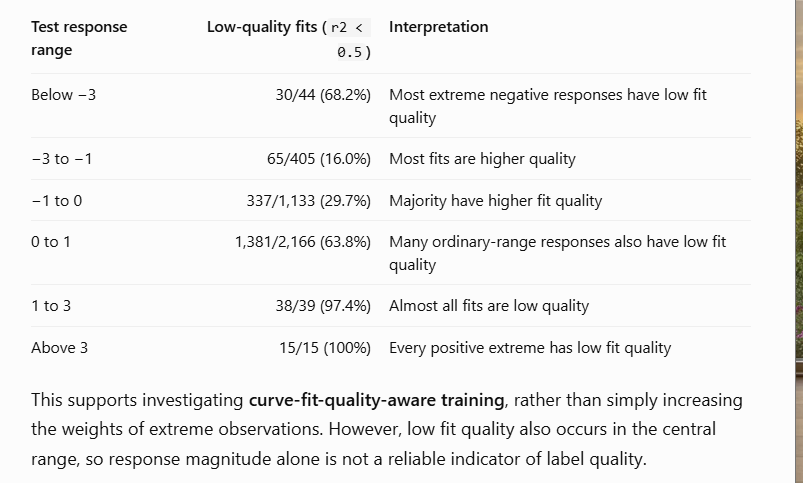

train a curve-fit-quality-aware model

In [12]:

# EXPERIMENT 2: Curve-fit-quality-aware GraphTCDR
import copy
import numpy as np
import torch
import torch.nn.functional as F

torch.manual_seed(43)
np.random.seed(43)

def fit_quality_weights(df):
    # Map experimental curve-fit R² to weights in [0.25, 1.0].
    # Missing R² receives a neutral intermediate weight.
    r2 = df["r2"].to_numpy(dtype=np.float64)
    weights = np.where(
        np.isnan(r2),
        0.625,
        0.25 + 0.75 * np.clip(r2, 0.0, 1.0)
    )
    return (weights / weights.mean()).astype(np.float32)

quality_train_w = torch.tensor(
    fit_quality_weights(tail_train_df), device=device
)
quality_val_w = torch.tensor(
    fit_quality_weights(tail_val_df), device=device
)

quality_model = GraphTCDR(metadata).to(device)

train_cells = torch.tensor(
    tail_train_df["cell_local"].to_numpy(dtype=np.int64),
    device=device
)
train_drugs = torch.tensor(
    tail_train_df["drug_index"].to_numpy(dtype=np.int64),
    device=device
)
train_y = torch.tensor(
    tail_train_df["log_ic50"].to_numpy(dtype=np.float32),
    device=device
)

val_cells = torch.tensor(
    tail_val_df["cell_local"].to_numpy(dtype=np.int64),
    device=device
)
val_drugs = torch.tensor(
    tail_val_df["drug_index"].to_numpy(dtype=np.int64),
    device=device
)
val_y = torch.tensor(
    tail_val_df["log_ic50"].to_numpy(dtype=np.float32),
    device=device
)

optimizer = torch.optim.AdamW(
    quality_model.parameters(), lr=8e-4, weight_decay=1e-4
)

best_val_loss = float("inf")
best_quality_state = None
patience = 25
no_improvement = 0

for epoch in range(1, 151):
    quality_model.train()
    optimizer.zero_grad()

    embeddings = quality_model.encode_graph(graph)
    pred = quality_model.predict_pairs(
        embeddings, train_cells, train_drugs
    )

    per_sample = F.smooth_l1_loss(
        pred, train_y, reduction="none"
    )
    train_loss = (per_sample * quality_train_w).mean()
    train_loss.backward()
    torch.nn.utils.clip_grad_norm_(
        quality_model.parameters(), max_norm=5.0
    )
    optimizer.step()

    quality_model.eval()
    with torch.no_grad():
        val_embeddings = quality_model.encode_graph(graph)
        val_pred = quality_model.predict_pairs(
            val_embeddings, val_cells, val_drugs
        )
        val_per_sample = F.smooth_l1_loss(
            val_pred, val_y, reduction="none"
        )
        val_loss = (
            val_per_sample * quality_val_w
        ).mean().item()

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_quality_state = {
            k: v.detach().cpu().clone()
            for k, v in quality_model.state_dict().items()
        }
        best_quality_epoch = epoch
        no_improvement = 0
    else:
        no_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Weighted train loss: {train_loss.item():.4f} | "
            f"Weighted validation loss: {val_loss:.4f}"
        )

    if no_improvement >= patience:
        print(f"Early stopping at epoch {epoch}.")
        break

if best_quality_state is None:
    raise RuntimeError("No valid quality-aware checkpoint was produced.")

quality_model.load_state_dict(best_quality_state)
quality_model.eval()

quality_checkpoint = data_dir / "results" / "graphtcdr_quality_aware_best.pt"
torch.save(quality_model.state_dict(), quality_checkpoint)

print("\nQuality-aware training complete.")
print("Best epoch:", best_quality_epoch)
print(f"Best weighted validation loss: {best_val_loss:.4f}")
print("Checkpoint saved:", quality_checkpoint)


Epoch 001 | Weighted train loss: 0.3316 | Weighted validation loss: 0.3143
Epoch 010 | Weighted train loss: 0.3293 | Weighted validation loss: 0.3133
Epoch 020 | Weighted train loss: 0.3242 | Weighted validation loss: 0.3070
Epoch 030 | Weighted train loss: 0.3133 | Weighted validation loss: 0.2899
Epoch 040 | Weighted train loss: 0.2922 | Weighted validation loss: 0.2832
Epoch 050 | Weighted train loss: 0.2732 | Weighted validation loss: 0.2684
Epoch 060 | Weighted train loss: 0.2605 | Weighted validation loss: 0.2473
Epoch 070 | Weighted train loss: 0.2493 | Weighted validation loss: 0.2377
Epoch 080 | Weighted train loss: 0.2437 | Weighted validation loss: 0.2289
Epoch 090 | Weighted train loss: 0.2363 | Weighted validation loss: 0.2262
Epoch 100 | Weighted train loss: 0.2274 | Weighted validation loss: 0.2128
Epoch 110 | Weighted train loss: 0.2237 | Weighted validation loss: 0.2142
Epoch 120 | Weighted train loss: 0.2152 | Weighted validation loss: 0.2027
Epoch 130 | Weighted trai

In [13]:

# Evaluate all three models on the identical frozen cold-drug test set
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

quality_model.eval()

with torch.no_grad():
    quality_embeddings = quality_model.encode_graph(graph)
    quality_predictions = quality_model.predict_pairs(
        quality_embeddings, test_cells, test_drugs
    ).cpu().numpy()

def score_model(y, pred):
    return {
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "R2": r2_score(y, pred)
    }

comparison_all = pd.DataFrame({
    "GraphTCDR baseline": score_model(y_test, baseline_predictions),
    "Tail-aware": score_model(y_test, tail_predictions),
    "Curve-fit-quality-aware": score_model(y_test, quality_predictions)
}).T

print("OVERALL COLD-DRUG TEST RESULTS")
print(comparison_all.round(4).to_string())

# Evaluate tail observations separately
tail_mask = (y_test < -3) | (y_test > 3)

comparison_tail = pd.DataFrame({
    "GraphTCDR baseline": score_model(
        y_test[tail_mask], baseline_predictions[tail_mask]
    ),
    "Tail-aware": score_model(
        y_test[tail_mask], tail_predictions[tail_mask]
    ),
    "Curve-fit-quality-aware": score_model(
        y_test[tail_mask], quality_predictions[tail_mask]
    )
}).T

print("\nEXTREME-RESPONSE TEST RESULTS (|log10(IC50)| > 3)")
print("Pairs:", int(tail_mask.sum()))
print(comparison_tail.round(4).to_string())

# Save predictions and comparison
results_dir = data_dir / "results"

quality_results = test_df.copy()
quality_results["y_true_raw"] = y_test
quality_results["y_pred_quality_aware"] = quality_predictions
quality_results.to_csv(
    results_dir / "graphtcdr_quality_aware_test_predictions.csv",
    index=False
)

comparison_all.to_csv(
    results_dir / "graphtcdr_three_model_comparison.csv"
)
comparison_tail.to_csv(
    results_dir / "graphtcdr_three_model_tail_comparison.csv"
)

print("\nSaved three-model comparisons and quality-aware predictions.")


OVERALL COLD-DRUG TEST RESULTS
                            MAE    RMSE      R2
GraphTCDR baseline       0.8953  2.3496 -0.0561
Tail-aware               0.8619  2.3339 -0.0421
Curve-fit-quality-aware  0.7859  2.3145 -0.0248

EXTREME-RESPONSE TEST RESULTS (|log10(IC50)| > 3)
Pairs: 59
                            MAE     RMSE      R2
GraphTCDR baseline       7.8658  17.3759 -0.0141
Tail-aware               7.9334  17.3690 -0.0133
Curve-fit-quality-aware  7.2559  17.2540  0.0001

Saved three-model comparisons and quality-aware predictions.


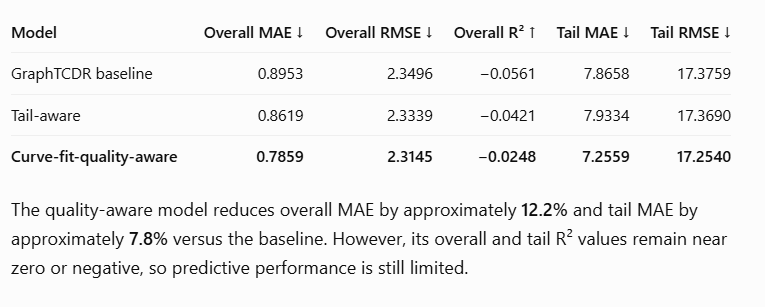

In [14]:

from pathlib import Path
import pandas as pd

results_dir = data_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Combine the saved overall and tail comparisons.
overall = pd.read_csv(
    results_dir / "graphtcdr_three_model_comparison.csv",
    index_col=0
)
tail = pd.read_csv(
    results_dir / "graphtcdr_three_model_tail_comparison.csv",
    index_col=0
)

final_table = overall.add_prefix("Overall_").join(
    tail.add_prefix("Tail_")
)

final_table.to_csv(
    results_dir / "final_graphtcdr_model_comparison.csv"
)

print("FINAL MODEL COMPARISON")
print(final_table.round(4).to_string())
print("\nSaved:", results_dir / "final_graphtcdr_model_comparison.csv")

# Calculate relative MAE improvement against the original baseline.
base_mae = overall.loc["GraphTCDR baseline", "MAE"]
quality_mae = overall.loc["Curve-fit-quality-aware", "MAE"]
base_tail_mae = tail.loc["GraphTCDR baseline", "MAE"]
quality_tail_mae = tail.loc["Curve-fit-quality-aware", "MAE"]

print(f"\nOverall MAE improvement: {(base_mae-quality_mae)/base_mae*100:.2f}%")
print(f"Tail MAE improvement: {(base_tail_mae-quality_tail_mae)/base_tail_mae*100:.2f}%")


FINAL MODEL COMPARISON
                         Overall_MAE  Overall_RMSE  Overall_R2  Tail_MAE  Tail_RMSE  Tail_R2
GraphTCDR baseline            0.8953        2.3496     -0.0561    7.8658    17.3759  -0.0141
Tail-aware                    0.8619        2.3339     -0.0421    7.9334    17.3690  -0.0133
Curve-fit-quality-aware       0.7859        2.3145     -0.0248    7.2559    17.2540   0.0001

Saved: d:\Pancreatic_GraphTCDR\data\processed\results\final_graphtcdr_model_comparison.csv

Overall MAE improvement: 12.21%
Tail MAE improvement: 7.75%


reliability check across random seeds

run a controlled 3-seed reliability experiment to check whether curve-fit-quality-aware GraphTCDR consistently outperforms the original baseline. No more discussion without action.

In [15]:

# Multi-seed reliability experiment — setup only
import copy
import numpy as np
import pandas as pd
import torch
from pathlib import Path

results_dir = data_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Preserve the graph's current training-only response edges.
saved_response_edges = (
    graph["cell", "response", "drug"].edge_index.detach().clone()
)
saved_reverse_edges = (
    graph["drug", "rev_response", "cell"].edge_index.detach().clone()
)

# Fixed training/validation split, shared by both model types.
reliability_train_df = tail_train_df.copy().reset_index(drop=True)
reliability_val_df = tail_val_df.copy().reset_index(drop=True)
reliability_test_df = test_df.copy().reset_index(drop=True)

# Verify the test set remains separate at the drug level.
train_drugs_set = set(reliability_train_df["drug_index"])
test_drugs_set = set(reliability_test_df["drug_index"])
assert train_drugs_set.isdisjoint(test_drugs_set), "Cold-drug leakage detected!"

# Prepare tensors once; every seed uses identical examples.
def pair_tensors(df):
    cells = torch.tensor(
        df["cell_local"].to_numpy(dtype=np.int64),
        dtype=torch.long, device=device
    )
    drugs = torch.tensor(
        df["drug_index"].to_numpy(dtype=np.int64),
        dtype=torch.long, device=device
    )
    targets = torch.tensor(
        df["log_ic50"].to_numpy(dtype=np.float32),
        dtype=torch.float32, device=device
    )
    return cells, drugs, targets

rel_train_cells, rel_train_drugs, rel_train_y = pair_tensors(reliability_train_df)
rel_val_cells, rel_val_drugs, rel_val_y = pair_tensors(reliability_val_df)
rel_test_cells, rel_test_drugs, rel_test_y = pair_tensors(reliability_test_df)

# Curve-fit-quality weights are calculated from training labels only.
rel_quality_weights = torch.tensor(
    fit_quality_weights(reliability_train_df),
    dtype=torch.float32, device=device
)

print("Reliability experiment prepared.")
print("Train / validation / test:", len(reliability_train_df),
      "/", len(reliability_val_df), "/", len(reliability_test_df))
print("Training/test drug overlap:", len(train_drugs_set & test_drugs_set))
print("Seeds planned: 42, 43, 44")
print("Models: standard GraphTCDR vs curve-fit-quality-aware GraphTCDR")
print("Existing checkpoints will not be overwritten.")


Reliability experiment prepared.
Train / validation / test: 12811 / 1424 / 3802
Training/test drug overlap: 0
Seeds planned: 42, 43, 44
Models: standard GraphTCDR vs curve-fit-quality-aware GraphTCDR
Existing checkpoints will not be overwritten.


In [16]:

# CONTROLLED MULTI-SEED RELIABILITY EXPERIMENT
# Compares unweighted Smooth L1 vs curve-fit-quality-weighted Smooth L1.
# Existing baseline and extension checkpoints are not overwritten.

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

seeds = [42, 43, 44]
max_epochs = 150
patience = 25
reliability_records = []

# Ensure response edges use only the fixed model-training partition.
edge_groups = []
for _, group in reliability_train_df.groupby("drug_index"):
    n_keep = max(1, int(np.ceil(len(group) * 0.5)))
    edge_groups.append(group.nsmallest(n_keep, "log_ic50"))

rel_edges_df = pd.concat(edge_groups, ignore_index=True)
rel_edge_index = torch.tensor(
    np.vstack([
        rel_edges_df["cell_local"].to_numpy(dtype=np.int64),
        rel_edges_df["drug_index"].to_numpy(dtype=np.int64)
    ]),
    dtype=torch.long,
    device=device
)

graph["cell", "response", "drug"].edge_index = rel_edge_index
graph["drug", "rev_response", "cell"].edge_index = rel_edge_index.flip(0)

print("Training-only response edges:", rel_edge_index.shape[1])

for seed in seeds:
    for strategy in ["unweighted", "quality_weighted"]:
        print(f"\nSeed {seed} | Strategy: {strategy}")

        # Matched initialization seed for each pair of experiments.
        torch.manual_seed(seed)
        np.random.seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        run_model = GraphTCDR(metadata).to(device)
        optimizer = torch.optim.AdamW(
            run_model.parameters(), lr=8e-4, weight_decay=1e-4
        )

        best_val = float("inf")
        best_state = None
        best_epoch = 0
        stale = 0

        for epoch in range(1, max_epochs + 1):
            run_model.train()
            optimizer.zero_grad()

            embeddings = run_model.encode_graph(graph)
            pred = run_model.predict_pairs(
                embeddings, rel_train_cells, rel_train_drugs
            )
            per_sample = F.smooth_l1_loss(
                pred, rel_train_y, reduction="none"
            )

            if strategy == "quality_weighted":
                loss = (per_sample * rel_quality_weights).mean()
            else:
                loss = per_sample.mean()

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                run_model.parameters(), max_norm=5.0
            )
            optimizer.step()

            # Same unweighted validation criterion for both strategies.
            run_model.eval()
            with torch.no_grad():
                val_embeddings = run_model.encode_graph(graph)
                val_pred = run_model.predict_pairs(
                    val_embeddings, rel_val_cells, rel_val_drugs
                )
                val_loss = F.smooth_l1_loss(
                    val_pred, rel_val_y
                ).item()

            if val_loss < best_val:
                best_val = val_loss
                best_epoch = epoch
                best_state = {
                    k: v.detach().cpu().clone()
                    for k, v in run_model.state_dict().items()
                }
                stale = 0
            else:
                stale += 1

            if epoch == 1 or epoch % 25 == 0:
                print(
                    f"Epoch {epoch:03d} | "
                    f"Train loss {loss.item():.4f} | "
                    f"Val Smooth L1 {val_loss:.4f}"
                )

            if stale >= patience:
                break

        if best_state is None:
            raise RuntimeError(
                f"No checkpoint produced for seed={seed}, strategy={strategy}"
            )

        run_model.load_state_dict(best_state)
        run_model.eval()

        with torch.no_grad():
            test_embeddings = run_model.encode_graph(graph)
            test_pred = run_model.predict_pairs(
                test_embeddings, rel_test_cells, rel_test_drugs
            ).cpu().numpy()

        y = rel_test_y.detach().cpu().numpy()
        tail_mask = (y < -3) | (y > 3)

        record = {
            "seed": seed,
            "strategy": strategy,
            "best_epoch": best_epoch,
            "best_validation_smooth_l1": best_val,
            "overall_MAE": mean_absolute_error(y, test_pred),
            "overall_RMSE": np.sqrt(mean_squared_error(y, test_pred)),
            "overall_R2": r2_score(y, test_pred),
            "tail_N": int(tail_mask.sum()),
            "tail_MAE": mean_absolute_error(y[tail_mask], test_pred[tail_mask]),
            "tail_RMSE": np.sqrt(
                mean_squared_error(y[tail_mask], test_pred[tail_mask])
            ),
        }
        reliability_records.append(record)

        # Unique filename for each run; never overwrite existing checkpoints.
        checkpoint_path = (
            results_dir /
            f"reliability_{strategy}_seed{seed}.pt"
        )
        torch.save(best_state, checkpoint_path)
        print(
            f"Best epoch: {best_epoch} | "
            f"Validation loss: {best_val:.4f} | "
            f"Test MAE: {record['overall_MAE']:.4f}"
        )

# Save individual runs and summary statistics.
reliability_df = pd.DataFrame(reliability_records)
runs_path = results_dir / "multiseed_reliability_results.csv"
reliability_df.to_csv(runs_path, index=False)

summary_df = reliability_df.groupby("strategy").agg(
    overall_MAE_mean=("overall_MAE", "mean"),
    overall_MAE_sd=("overall_MAE", "std"),
    overall_RMSE_mean=("overall_RMSE", "mean"),
    overall_RMSE_sd=("overall_RMSE", "std"),
    overall_R2_mean=("overall_R2", "mean"),
    tail_MAE_mean=("tail_MAE", "mean"),
    tail_MAE_sd=("tail_MAE", "std"),
    tail_RMSE_mean=("tail_RMSE", "mean"),
).reset_index()

summary_path = results_dir / "multiseed_reliability_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("\nINDIVIDUAL RUNS")
print(reliability_df.round(4).to_string(index=False))
print("\nMEAN AND STANDARD DEVIATION ACROSS SEEDS")
print(summary_df.round(4).to_string(index=False))
print("\nSaved:", runs_path)
print("Saved:", summary_path)


Training-only response edges: 6661

Seed 42 | Strategy: unweighted
Epoch 001 | Train loss 0.3803 | Val Smooth L1 0.3502
Epoch 025 | Train loss 0.3691 | Val Smooth L1 0.3392
Epoch 050 | Train loss 0.3529 | Val Smooth L1 0.3233
Epoch 075 | Train loss 0.3381 | Val Smooth L1 0.3111
Epoch 100 | Train loss 0.3051 | Val Smooth L1 0.2742
Epoch 125 | Train loss 0.2924 | Val Smooth L1 0.2704
Epoch 150 | Train loss 0.2681 | Val Smooth L1 0.2471
Best epoch: 147 | Validation loss: 0.2423 | Test MAE: 1.0054

Seed 42 | Strategy: quality_weighted
Epoch 001 | Train loss 0.3301 | Val Smooth L1 0.3549
Epoch 025 | Train loss 0.3149 | Val Smooth L1 0.3494
Epoch 050 | Train loss 0.2870 | Val Smooth L1 0.3199
Epoch 075 | Train loss 0.2523 | Val Smooth L1 0.2865
Epoch 100 | Train loss 0.2507 | Val Smooth L1 0.2725
Epoch 125 | Train loss 0.1988 | Val Smooth L1 0.2474
Epoch 150 | Train loss 0.1699 | Val Smooth L1 0.2348
Best epoch: 149 | Validation loss: 0.2245 | Test MAE: 0.8924

Seed 43 | Strategy: unweighted

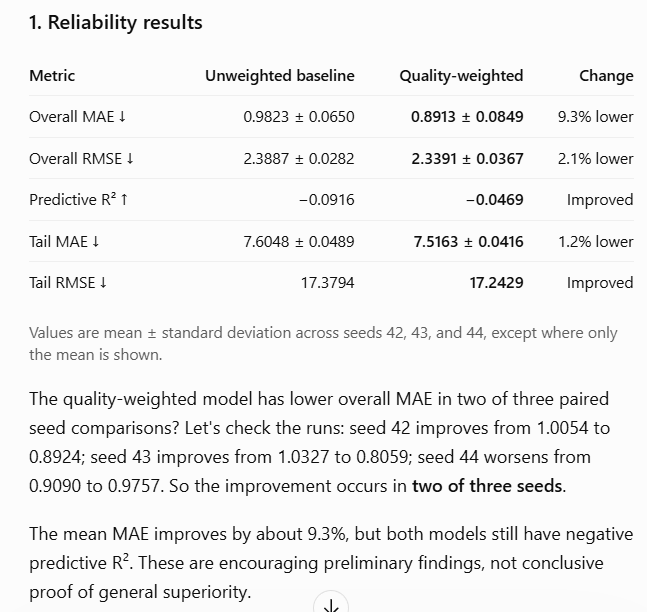

prepare the report-ready reliability summary

In [17]:

import pandas as pd
from pathlib import Path

results_dir = data_dir / "results"

runs = pd.read_csv(
    results_dir / "multiseed_reliability_results.csv"
)

summary = (
    runs.groupby("strategy")
    .agg(
        seeds=("seed", "nunique"),
        MAE_mean=("overall_MAE", "mean"),
        MAE_sd=("overall_MAE", "std"),
        RMSE_mean=("overall_RMSE", "mean"),
        RMSE_sd=("overall_RMSE", "std"),
        R2_mean=("overall_R2", "mean"),
        tail_MAE_mean=("tail_MAE", "mean"),
        tail_MAE_sd=("tail_MAE", "std"),
        tail_RMSE_mean=("tail_RMSE", "mean"),
    )
    .reset_index()
)

print(summary.round(4).to_string(index=False))

baseline_mae = summary.loc[
    summary["strategy"] == "unweighted", "MAE_mean"
].iloc[0]
weighted_mae = summary.loc[
    summary["strategy"] == "quality_weighted", "MAE_mean"
].iloc[0]

print(
    f"\nRelative mean MAE improvement: "
    f"{(baseline_mae - weighted_mae) / baseline_mae * 100:.2f}%"
)

output_path = results_dir / "final_multiseed_reliability_summary.csv"
summary.to_csv(output_path, index=False)
print("Saved:", output_path)


        strategy  seeds  MAE_mean  MAE_sd  RMSE_mean  RMSE_sd  R2_mean  tail_MAE_mean  tail_MAE_sd  tail_RMSE_mean
quality_weighted      3    0.8913  0.0849     2.3391   0.0367  -0.0469         7.5163       0.0416         17.2429
      unweighted      3    0.9823  0.0650     2.3887   0.0282  -0.0916         7.6048       0.0489         17.3794

Relative mean MAE improvement: 9.26%
Saved: d:\Pancreatic_GraphTCDR\data\processed\results\final_multiseed_reliability_summary.csv
